# California home value

`fetch_california_housing` is a scikit-learn dataset built from the 1990 US census. Each row is one California block group, the smallest area the census publishes, not one house. `MedHouseVal` is the target, the median house value in hundreds of thousands of dollars. The other eight columns are `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, and `Longitude`.

A linear regression on those eight columns is the baseline.

KMeans regions on latitude and longitude are then added. The region count is chosen on the training block groups, and Lasso is fit on the same regions.

Gradient boosting is fit on the eight columns, then searched more widely, with a region category and a bedroom ratio.

The five lines are compared on the held-out block groups.



## Load the dataset


In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

california = fetch_california_housing(as_frame=True)
df = california.frame
print(df.shape)
print(df.columns.tolist())


(20640, 9)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


## Inspect the data

`df` is `california.frame`, the eight features and `MedHouseVal` together. There are 20,640 rows, 9 columns, and no missing values. Every column is a float, so there is no encoding to do.

`AveRooms`, `AveBedrms`, and `AveOccup` are averages per household inside a block group, not per house, so a block group with few households can push these far above a normal house. The 75th percentile of `AveRooms` is 6.05, but the max is 141.91. `AveOccup` runs from 0.69 to 1,243.33 the same way.

The model keeps all eight feature columns and predicts `MedHouseVal`.


In [2]:
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population

## Investigate the target

The dataset description below gives the units and the geography.


In [3]:
print(california.DESCR[:2000])


.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

The description does not say outright whether the target is capped. Count the rows sitting exactly at the maximum to check.


In [4]:
print(df["MedHouseVal"].max())
print((df["MedHouseVal"] == df["MedHouseVal"].max()).sum())


5.00001
965


The maximum is 5.00001, and 965 of the 20,640 block groups sit exactly there, 4.7% of the data. The target is capped at $500,001: any block group whose true median value was higher is recorded at that ceiling. Those 965 rows have no real top price to learn, only the cap.


In [5]:
print(df["MedHouseVal"].agg(["min", "median", "mean", "max", "std"]).round(3))
print()
print(df.corr()["MedHouseVal"].round(3))


min       0.150
median    1.797
mean      2.069
max       5.000
std       1.154
Name: MedHouseVal, dtype: float64

MedInc         0.688
HouseAge       0.106
AveRooms       0.152
AveBedrms     -0.047
Population    -0.025
AveOccup      -0.024
Latitude      -0.144
Longitude     -0.046
MedHouseVal    1.000
Name: MedHouseVal, dtype: float64


`MedHouseVal` runs from 0.150 to 5.000, median 1.797, mean 2.069. The mean sits above the median, so the capped high end pulls it up. The standard deviation is 1.154, large next to a median of 1.797.

`MedInc` correlates with the target at 0.688, far above every other column. `AveRooms` is 0.152 and `HouseAge` is 0.106. `Latitude` is -0.144: house values fall moving north. `AveBedrms`, `Population`, `AveOccup`, and `Longitude` are all under 0.05 in size and tell little on their own.


## Visualise relationships

The pairplot crosses `MedHouseVal` with the eight features. `MedInc` rises with the target. The other columns are looser, and the cap sits as a line of block groups at 5.


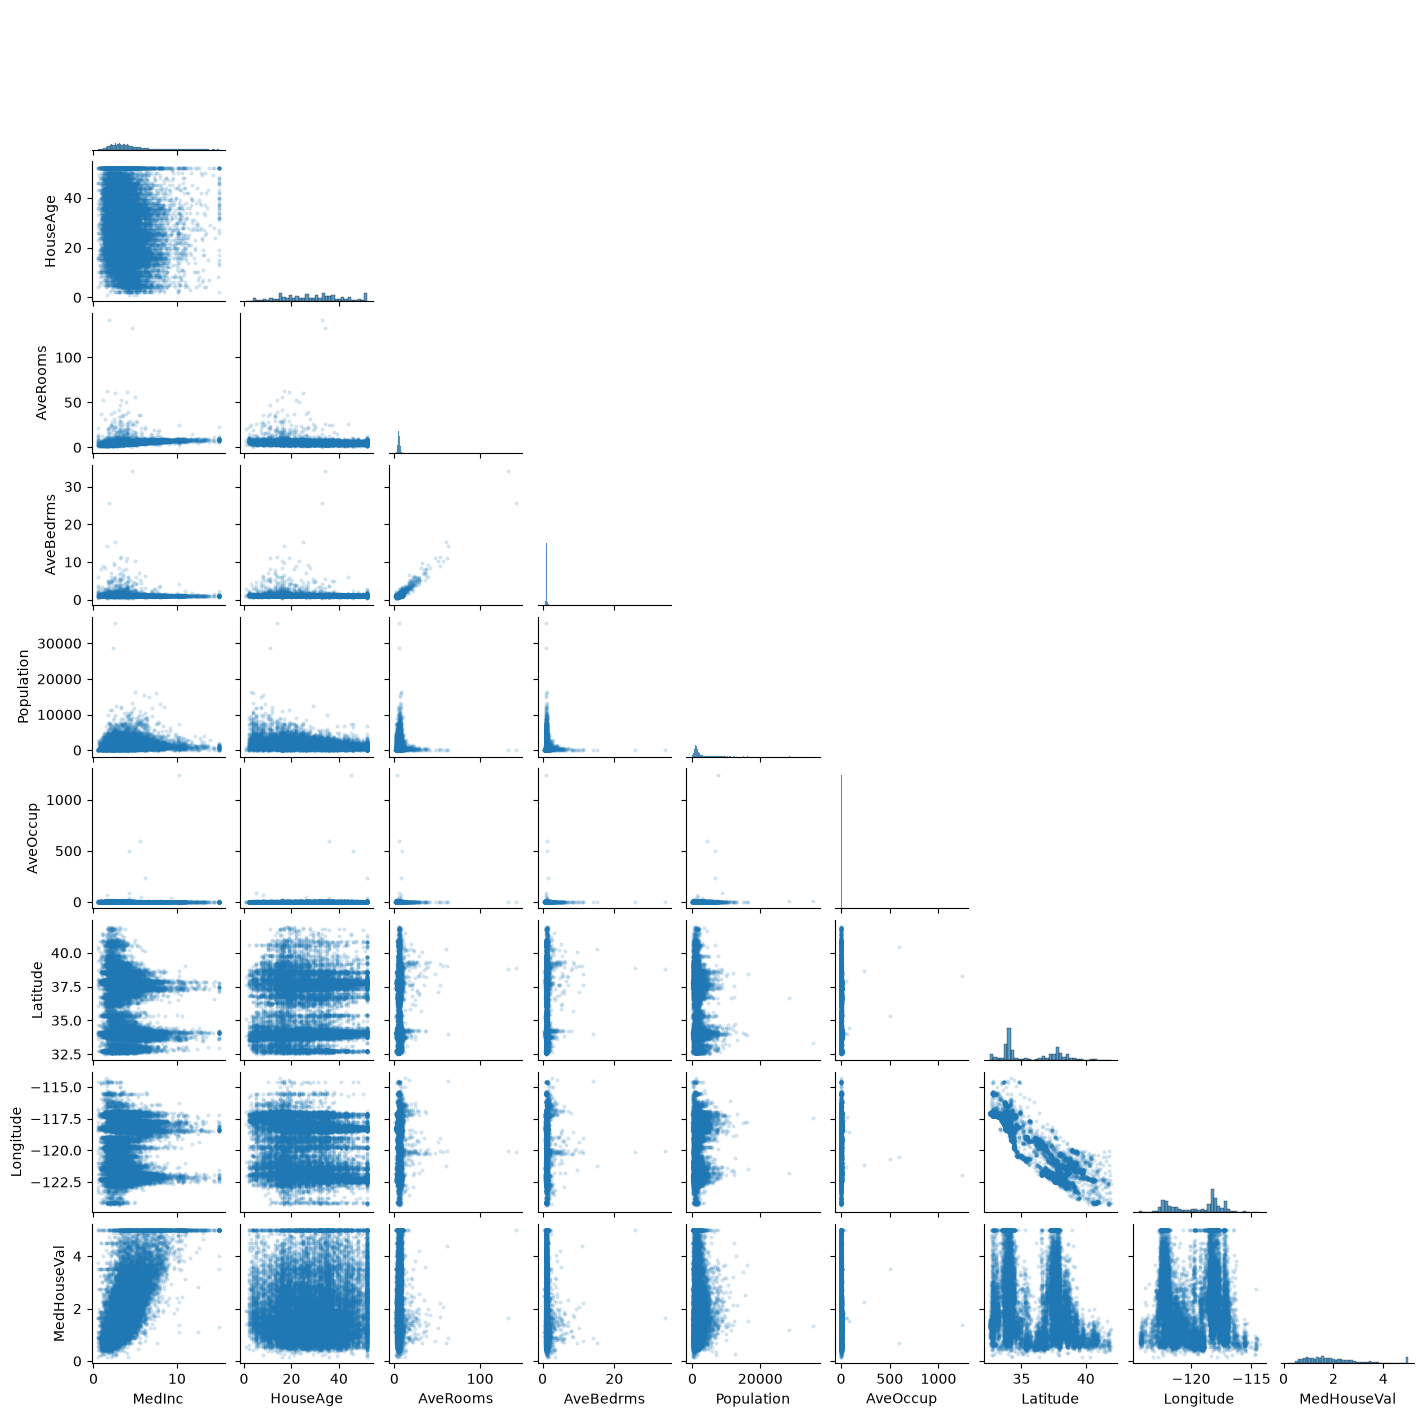

In [6]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    df,
    corner=True,
    diag_kind="hist",
    height=1.6,
    plot_kws={"s": 8, "alpha": 0.2, "linewidth": 0, "color": "#1F78B4"},
    diag_kws={"color": "#1F78B4"},
)
plt.show()


## Train and test split

Hold out 20% of the block groups. `MedHouseVal` is continuous, so the split is not stratified.


In [18]:
from sklearn.model_selection import train_test_split

feature_columns = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude",
]
features = df[feature_columns]
labels = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42
)
print("Train:", X_train.shape[0], "Test:", X_test.shape[0])
print(y_train.agg(["min", "median", "mean", "max"]).round(3))
print(y_test.agg(["min", "median", "mean", "max"]).round(3))


Train: 16512 Test: 4128
min       0.150
median    1.798
mean      2.072
max       5.000
Name: MedHouseVal, dtype: float64
min       0.150
median    1.786
mean      2.055
max       5.000
Name: MedHouseVal, dtype: float64


16,512 block groups train the model and 4,128 are held out. Training median is 1.798 and mean 2.072. Test median is 1.786 and mean 2.055, close to training.


## Baseline linear regression

One plain linear regression on all eight features, nothing else. Every feature is scaled on the training block groups before the fit.


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

baseline = Pipeline([
    ("scale", StandardScaler()),
    ("regress", LinearRegression()),
])
baseline.fit(X_train, y_train)

train_predicted = baseline.predict(X_train)
test_predicted = baseline.predict(X_test)

print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
print(f'R2: {r2_score(y_test, test_predicted):.3f}')
print(f'Mean absolute error: {mean_absolute_error(y_test, test_predicted):.3f}')


Train R2: 0.613
R2: 0.576
Mean absolute error: 0.533


Train R² is 0.613 and test R² is 0.576, so the line explains a bit more than half of the variation in house value. The test mean absolute error is 0.533, about 30% of the test median of 1.786. That is a loose baseline, not yet good enough to price one block group.


## How many regions?

30 was a guess. Search for a better region count instead of picking it by hand. Score each candidate by 5-fold average R2 of the linear regression plus region one-hot, on the training block groups only. A coarse doubling pass (5, 10, 20, ... 1000) finds the neighborhood of the best count, then a ternary search narrows that neighborhood, since the fold score rises, peaks, and falls as the region count grows.


In [20]:
import warnings

import numpy as np

from sklearn.cluster import KMeans

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", message="Found unknown categories")


def region_pipeline(estimator):
    return Pipeline([
        (
            "preprocess",
            ColumnTransformer([
                ("numeric", StandardScaler(), feature_columns),
                (
                    "region",
                    OneHotEncoder(
                        drop="first", sparse_output=False, handle_unknown="ignore"
                    ),
                    ["Region"],
                ),
            ]),
        ),
        ("regress", estimator),
    ])


search_folds = KFold(n_splits=5, shuffle=True, random_state=42)
search_cache = {}


def region_fold_r2(k):
    if k in search_cache:
        return search_cache[k]
    search_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    search_model.fit(X_train[["Latitude", "Longitude"]])
    region_labels = search_model.predict(
        X_train[["Latitude", "Longitude"]]
    ).astype(str)
    X_train_k = X_train.copy()
    X_train_k["Region"] = region_labels

    fold_r2 = []
    for train_index, valid_index in search_folds.split(X_train_k):
        pipeline = region_pipeline(LinearRegression())
        pipeline.fit(X_train_k.iloc[train_index], y_train.iloc[train_index])
        predicted = pipeline.predict(X_train_k.iloc[valid_index])
        fold_r2.append(r2_score(y_train.iloc[valid_index], predicted))
    score = float(np.mean(fold_r2))
    search_cache[k] = score
    return score


coarse_candidates = [5, 10, 20, 40, 80, 160, 320, 640, 1000]
for k in coarse_candidates:
    print(f"k={k}: fold R2 {region_fold_r2(k):.4f}")

ranked = sorted(coarse_candidates, key=lambda k: search_cache[k], reverse=True)
best_coarse = ranked[0]
coarse_idx = coarse_candidates.index(best_coarse)
low = coarse_candidates[max(coarse_idx - 1, 0)]
high = coarse_candidates[min(coarse_idx + 1, len(coarse_candidates) - 1)]
print(f"Best coarse k: {best_coarse}, refine between {low} and {high}")

while high - low > 40:
    mid1 = low + (high - low) // 3
    mid2 = high - (high - low) // 3
    if mid1 == mid2:
        mid2 += 1
    score1 = region_fold_r2(mid1)
    score2 = region_fold_r2(mid2)
    print(
        f"low={low} high={high}: k={mid1} R2 {score1:.4f}, "
        f"k={mid2} R2 {score2:.4f}"
    )
    if score1 < score2:
        low = mid1
    else:
        high = mid2

best_k = max(search_cache, key=search_cache.get)
print()
print(f"Chosen region count: {best_k}, fold R2 {search_cache[best_k]:.4f}")


k=5: fold R2 0.6221
k=10: fold R2 0.6265
k=20: fold R2 0.6484
k=40: fold R2 0.6693
k=80: fold R2 0.7006
k=160: fold R2 0.7351
k=320: fold R2 0.7644
k=640: fold R2 0.7824
k=1000: fold R2 0.7729
Best coarse k: 640, refine between 320 and 1000
low=320 high=1000: k=546 R2 0.7766, k=774 R2 0.7737
low=320 high=774: k=471 R2 0.7697, k=623 R2 0.7805
low=471 high=774: k=572 R2 0.7787, k=673 R2 0.7664
low=471 high=673: k=538 R2 0.7652, k=606 R2 0.7849
low=538 high=673: k=583 R2 0.7789, k=628 R2 0.7787
low=538 high=628: k=568 R2 0.7751, k=598 R2 0.7782
low=568 high=628: k=588 R2 0.7769, k=608 R2 0.7788

Chosen region count: 606, fold R2 0.7849


The coarse doubling pass rises the whole way: fold R2 is 0.622 at 5 regions, 0.649 at 20, 0.700 at 80, 0.735 at 160, 0.764 at 320, peaks at 0.782 at 640, then falls back to 0.773 at 1000. That peak at 640 brackets the search between 320 and 1000.

The ternary refinement narrows that bracket by testing two interior points each round and dropping the worse side: 546 vs 774, then 471 vs 623, then 572 vs 673, then 538 vs 606, then 583 vs 628, then 568 vs 598, until the bracket is 40 wide. The single best point seen anywhere in the search is **606 regions, fold R2 0.7849**, clearly ahead of the fold score a fixed guess of 30 regions would have given.


KMeans groups the training block groups into 606 regions, the count the search above found, using only Latitude and Longitude. The same fitted clusterer then labels the test block groups, so no test coordinate shapes the regions.


In [21]:
from sklearn.cluster import KMeans

region_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
region_model.fit(X_train[["Latitude", "Longitude"]])

X_train_region = X_train.copy()
X_test_region = X_test.copy()
X_train_region["Region"] = region_model.predict(
    X_train_region[["Latitude", "Longitude"]]
).astype(str)
X_test_region["Region"] = region_model.predict(
    X_test_region[["Latitude", "Longitude"]]
).astype(str)

print(X_train_region["Region"].value_counts().sort_index())


Region
0      96
1      10
10     16
100    43
101    21
       ..
95     21
96     89
97      3
98      7
99      6
Name: count, Length: 606, dtype: int64


The 606 regions range from 1 training block group to 172, mean 27.2, median 15. 144 regions hold fewer than 5 block groups, and 42 are a single block group alone. That is the tradeoff for the higher fold score: many regions are now so small they are closer to memorizing one location than describing a neighborhood.


The eight original features stay, scaled the same way as the baseline. Region becomes 605 one-hot columns, one region dropped as the reference.


In [22]:
region_linear = region_pipeline(LinearRegression())
region_linear.fit(X_train_region, y_train)

train_predicted = region_linear.predict(X_train_region)
test_predicted = region_linear.predict(X_test_region)

print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
print(f'R2: {r2_score(y_test, test_predicted):.3f}')
print(f'Mean absolute error: {mean_absolute_error(y_test, test_predicted):.3f}')


Train R2: 0.801
R2: 0.788
Mean absolute error: 0.362


Train R2 rises from 0.613 to 0.801 and test R2 rises from 0.576 to 0.788. The test mean absolute error drops from 0.533 to 0.362. The searched 606 regions beat the earlier guesses by a wide margin: test R2 was 0.604 at 15 regions and 0.643 at 30. Letting the region count grow until the fold score stops improving was worth far more than doubling a hand-picked guess.


## Lasso (L1) regression

Lasso uses the same eight features and the region one-hot. Five training folds compare a grid of `alpha` values. The held-out block groups are scored once, after the best `alpha` is chosen from the folds alone.


In [23]:
import numpy as np

from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold

lasso_folds = KFold(n_splits=5, shuffle=True, random_state=42)
lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
lasso_grid = []
for alpha in lasso_alphas:
    fold_r2 = []
    fold_mae = []
    for train_index, valid_index in lasso_folds.split(X_train_region):
        fold_model = region_pipeline(Lasso(alpha=alpha, max_iter=20000))
        fold_model.fit(
            X_train_region.iloc[train_index], y_train.iloc[train_index]
        )
        predicted = fold_model.predict(X_train_region.iloc[valid_index])
        truth = y_train.iloc[valid_index]
        fold_r2.append(r2_score(truth, predicted))
        fold_mae.append(mean_absolute_error(truth, predicted))
    print(
        f'alpha {alpha}: R2 {np.mean(fold_r2):.3f}, '
        f'MAE {np.mean(fold_mae):.3f}'
    )
    lasso_grid.append((np.mean(fold_r2), np.mean(fold_mae), alpha))

lasso_grid.sort(key=lambda row: row[0], reverse=True)
best_alpha = lasso_grid[0][2]
print('Chosen alpha:', best_alpha)


alpha 0.001: R2 0.725, MAE 0.440
alpha 0.01: R2 0.616, MAE 0.528
alpha 0.05: R2 0.547, MAE 0.579
alpha 0.1: R2 0.497, MAE 0.619
alpha 0.5: R2 0.290, MAE 0.766
alpha 1.0: R2 -0.000, MAE 0.914
Chosen alpha: 0.001


Fold R2 falls as alpha grows: 0.725 at alpha 0.001, 0.616 at 0.01, 0.547 at 0.05, 0.497 at 0.1, 0.290 at 0.5, and 0.000 at 1.0, where Lasso has shrunk every coefficient to zero and just predicts the mean. The folds still pick the smallest alpha, 0.001, but that fold score, 0.725, now sits clearly below the unregularized 606-region fold score of 0.7849.


In [24]:
best_lasso = region_pipeline(Lasso(alpha=best_alpha, max_iter=20000))
best_lasso.fit(X_train_region, y_train)

train_predicted = best_lasso.predict(X_train_region)
test_predicted = best_lasso.predict(X_test_region)

print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
print(f'R2: {r2_score(y_test, test_predicted):.3f}')
print(f'Mean absolute error: {mean_absolute_error(y_test, test_predicted):.3f}')


Train R2: 0.731
R2: 0.711
Mean absolute error: 0.440


Train R2 0.731, test R2 0.711, mean absolute error 0.440.

At the earlier fixed 30-region fit, Lasso barely changed anything: the feature set of 8 numeric columns and 29 region dummies did not have much useless or redundant signal to prune, so alpha 0.001 landed within 0.001 of the plain line. At 606 regions that is no longer true. The one-hot block grows to 605 columns, most of them built from a handful of block groups, and plain linear regression fits every one of those small, noisy columns exactly, which is how it reaches test R2 0.788. Even the lightest Lasso penalty shrinks those small-cluster coefficients back toward zero, and test R2 drops to 0.711, a real gap of 0.077 instead of 0.001. More regions did not just add more signal to prune, it added more coefficients that only the unregularized line was willing to trust completely.


## Gradient boosting

`HistGradientBoostingRegressor` fits on the eight raw features, unscaled, no region column. Trees split on `Latitude` and `Longitude` directly, so a hand-made region does not help them the way it helps the linear lines. Five training folds compare `learning_rate` and `max_depth`.


In [25]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_folds = KFold(n_splits=5, shuffle=True, random_state=42)
hgb_grid = []
for learning_rate in [0.05, 0.1]:
    for max_depth in [3, 6, None]:
        fold_r2 = []
        fold_mae = []
        for train_index, valid_index in hgb_folds.split(X_train):
            model = HistGradientBoostingRegressor(
                learning_rate=learning_rate,
                max_depth=max_depth,
                random_state=42,
            )
            model.fit(
                X_train.iloc[train_index], y_train.iloc[train_index]
            )
            predicted = model.predict(X_train.iloc[valid_index])
            truth = y_train.iloc[valid_index]
            fold_r2.append(r2_score(truth, predicted))
            fold_mae.append(mean_absolute_error(truth, predicted))
        depth_label = "none" if max_depth is None else str(max_depth)
        print(
            f'learning_rate {learning_rate}, depth {depth_label}: '
            f'R2 {np.mean(fold_r2):.3f}, MAE {np.mean(fold_mae):.3f}'
        )
        hgb_grid.append(
            (np.mean(fold_r2), np.mean(fold_mae), learning_rate, max_depth)
        )

hgb_grid.sort(key=lambda row: row[0], reverse=True)
best_learning_rate = hgb_grid[0][2]
best_max_depth = hgb_grid[0][3]
print('Chosen learning_rate:', best_learning_rate, 'max_depth:', best_max_depth)


learning_rate 0.05, depth 3: R2 0.754, MAE 0.406
learning_rate 0.05, depth 6: R2 0.809, MAE 0.344
learning_rate 0.05, depth none: R2 0.820, MAE 0.333
learning_rate 0.1, depth 3: R2 0.787, MAE 0.370
learning_rate 0.1, depth 6: R2 0.827, MAE 0.323
learning_rate 0.1, depth none: R2 0.832, MAE 0.316
Chosen learning_rate: 0.1 max_depth: None


Fold R2 rises with both a higher learning rate and deeper trees: 0.754 at learning_rate 0.05 and depth 3, up to 0.832 at learning_rate 0.1 and unlimited depth. The folds pick learning_rate 0.1 and max_depth None.


In [26]:
best_hgb = HistGradientBoostingRegressor(
    learning_rate=best_learning_rate,
    max_depth=best_max_depth,
    random_state=42,
)
best_hgb.fit(X_train, y_train)

train_predicted = best_hgb.predict(X_train)
test_predicted = best_hgb.predict(X_test)

print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
print(f'R2: {r2_score(y_test, test_predicted):.3f}')
print(f'Mean absolute error: {mean_absolute_error(y_test, test_predicted):.3f}')


Train R2: 0.880
R2: 0.835
Mean absolute error: 0.311


Train R2 0.880, test R2 0.835, mean absolute error 0.311. That is well above every linear line, on both R2 and the miss.


## Improving gradient boosting further

The grid above only tried two `learning_rate` values and three `max_depth` values, and the winner sat at both edges: the highest learning rate tried and the least constrained depth. That is a sign the grid was too narrow. Three changes at once: a ratio feature, a geographic category, and a wider hyperparameter search.

`BedroomRatio` is `AveBedrms / AveRooms`, a single engineered column. The region label is fed to the booster as a native category, not a one-hot block. `HistGradientBoostingRegressor` caps a categorical column at 255 distinct values, below the 606 regions chosen earlier for the linear line, so a separate, coarser clustering, 200 regions, is fit just for this feature.

The search itself widens too: `RandomizedSearchCV` over `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, and `l2_regularization`, 25 random draws, scored on the same 5-fold split as every other model here. `max_iter` is fixed high, 1000, with early stopping deciding how many trees to actually grow, instead of picking a tree count by hand.


In [27]:
from sklearn.cluster import KMeans

gb_region_model = KMeans(n_clusters=200, random_state=42, n_init=10)
gb_region_model.fit(X_train[["Latitude", "Longitude"]])

X_train_ratio = X_train.copy()
X_test_ratio = X_test.copy()
X_train_ratio["BedroomRatio"] = (
    X_train_ratio["AveBedrms"] / X_train_ratio["AveRooms"]
)
X_test_ratio["BedroomRatio"] = (
    X_test_ratio["AveBedrms"] / X_test_ratio["AveRooms"]
)

X_train_gbregion = X_train.copy()
X_test_gbregion = X_test.copy()
X_train_gbregion["Region"] = gb_region_model.predict(
    X_train_gbregion[["Latitude", "Longitude"]]
).astype(str)
X_train_gbregion["Region"] = X_train_gbregion["Region"].astype("category")
X_test_gbregion["Region"] = gb_region_model.predict(
    X_test_gbregion[["Latitude", "Longitude"]]
).astype(str)
X_test_gbregion["Region"] = X_test_gbregion["Region"].astype(
    X_train_gbregion["Region"].dtype
)

X_train_gball = X_train_gbregion.copy()
X_test_gball = X_test_gbregion.copy()
X_train_gball["BedroomRatio"] = (
    X_train_gball["AveBedrms"] / X_train_gball["AveRooms"]
)
X_test_gball["BedroomRatio"] = (
    X_test_gball["AveBedrms"] / X_test_gball["AveRooms"]
)

print(X_train_gball.dtypes)


MedInc           float64
HouseAge         float64
AveRooms         float64
AveBedrms        float64
Population       float64
AveOccup         float64
Latitude         float64
Longitude        float64
Region          category
BedroomRatio     float64
dtype: object


Four feature sets go through the same broadened search: the eight raw features alone, raw plus `BedroomRatio`, raw plus the `Region` category, and all three together. That separates what the wider search alone buys from what each new feature buys.


In [28]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

gb_param_distributions = {
    "learning_rate": loguniform(0.02, 0.3),
    "max_leaf_nodes": randint(15, 255),
    "min_samples_leaf": randint(5, 60),
    "l2_regularization": loguniform(1e-3, 10),
}
gb_search_folds = KFold(n_splits=5, shuffle=True, random_state=42)


def run_gb_search(X_train_variant, X_test_variant):
    base_model = HistGradientBoostingRegressor(
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=15,
        validation_fraction=0.1,
        random_state=42,
    )
    search = RandomizedSearchCV(
        base_model,
        param_distributions=gb_param_distributions,
        n_iter=25,
        cv=gb_search_folds,
        scoring="r2",
        random_state=42,
        n_jobs=-1,
    )
    search.fit(X_train_variant, y_train)
    best_model = search.best_estimator_
    train_predicted = best_model.predict(X_train_variant)
    test_predicted = best_model.predict(X_test_variant)
    return search, {
        "cv_r2": search.best_score_,
        "train_r2": r2_score(y_train, train_predicted),
        "test_r2": r2_score(y_test, test_predicted),
        "test_mae": mean_absolute_error(y_test, test_predicted),
        "trees": best_model.n_iter_,
    }


gb_variants = {
    "Raw 8 features": (X_train, X_test),
    "+ BedroomRatio": (X_train_ratio, X_test_ratio),
    "+ Region category": (X_train_gbregion, X_test_gbregion),
    "+ both": (X_train_gball, X_test_gball),
}

gb_searches = {}
gb_rows = []
for name, (train_variant, test_variant) in gb_variants.items():
    search, row = run_gb_search(train_variant, test_variant)
    row["variant"] = name
    gb_searches[name] = search
    gb_rows.append(row)

gb_ablation = pd.DataFrame(gb_rows)[
    ["variant", "cv_r2", "train_r2", "test_r2", "test_mae", "trees"]
]
print(gb_ablation.round(3).to_string(index=False))


          variant  cv_r2  train_r2  test_r2  test_mae  trees
   Raw 8 features  0.843     0.926    0.847     0.291    783
   + BedroomRatio  0.845     0.916    0.847     0.294    256
+ Region category  0.849     0.947    0.855     0.284    213
           + both  0.851     0.948    0.854     0.282    213


The wider search alone, on the same eight raw features, already beats the earlier fixed grid: cv R2 0.843 against the old grid pick's fold-equivalent result, test R2 0.847 against 0.835, mean absolute error 0.291 against 0.311. Adding BedroomRatio alone barely moves anything, cv R2 0.845, test R2 0.847, the same to three decimals: trees can already approximate that ratio with a couple of splits on AveBedrms and AveRooms separately, so a precomputed ratio column buys little. The Region category is the real win, cv R2 0.849, test R2 0.855: a single categorical split can do what many Latitude/Longitude splits were approximating before. Combining both features lands at test R2 0.854, tied with region alone within noise. Early stopping also picked very different tree counts across variants, from 213 up to 783, instead of a fixed max_iter.


In [29]:
best_variant = gb_ablation.sort_values("cv_r2", ascending=False).iloc[0][
    "variant"
]
best_gb_search = gb_searches[best_variant]
best_gb = best_gb_search.best_estimator_
best_X_train_gb, best_X_test_gb = gb_variants[best_variant]

print("Best variant:", best_variant)
print("Best params:", best_gb_search.best_params_)
print("Trees actually grown:", best_gb.n_iter_)

train_predicted = best_gb.predict(best_X_train_gb)
test_predicted = best_gb.predict(best_X_test_gb)
print(f'Train R2: {r2_score(y_train, train_predicted):.3f}')
print(f'R2: {r2_score(y_test, test_predicted):.3f}')
print(f'Mean absolute error: {mean_absolute_error(y_test, test_predicted):.3f}')


Best variant: + both
Best params: {'l2_regularization': np.float64(0.2975390947349387), 'learning_rate': np.float64(0.056343030242230155), 'max_leaf_nodes': 78, 'min_samples_leaf': 7}
Trees actually grown: 213
Train R2: 0.948
R2: 0.854
Mean absolute error: 0.282


+ both has the best cv R2, so that is the final model: BedroomRatio plus the 200-region category, learning_rate 0.056, max_leaf_nodes 78, min_samples_leaf 7, l2_regularization 0.298, stopped early at 213 trees. Train R2 0.948, test R2 0.854, mean absolute error 0.282. Against the original fixed grid, test R2 rises from 0.835 to 0.854 and the miss falls from 0.311 to 0.282, a 9% drop in mean absolute error from widening the search and handing the booster one new categorical feature.


## Compare all five

The same 80/20 split scores every line: the baseline, linear regression with region clusters, Lasso with region clusters, the first gradient boosting grid, and the improved gradient boosting from the previous section.


In [30]:
comparison = pd.DataFrame(
    [
        {
            "model": "Baseline linear",
            "train_r2": r2_score(y_train, baseline.predict(X_train)),
            "test_r2": r2_score(
                y_test, baseline.predict(X_test)
            ),
            "test_mae": mean_absolute_error(
                y_test, baseline.predict(X_test)
            ),
        },
        {
            "model": "Linear + regions",
            "train_r2": r2_score(
                y_train, region_linear.predict(X_train_region)
            ),
            "test_r2": r2_score(
                y_test, region_linear.predict(X_test_region)
            ),
            "test_mae": mean_absolute_error(
                y_test, region_linear.predict(X_test_region)
            ),
        },
        {
            "model": "Lasso + regions",
            "train_r2": r2_score(
                y_train, best_lasso.predict(X_train_region)
            ),
            "test_r2": r2_score(
                y_test, best_lasso.predict(X_test_region)
            ),
            "test_mae": mean_absolute_error(
                y_test, best_lasso.predict(X_test_region)
            ),
        },
        {
            "model": "Gradient boosting",
            "train_r2": r2_score(y_train, best_hgb.predict(X_train)),
            "test_r2": r2_score(y_test, best_hgb.predict(X_test)),
            "test_mae": mean_absolute_error(
                y_test, best_hgb.predict(X_test)
            ),
        },
        {
            "model": "Gradient boosting (improved)",
            "train_r2": r2_score(
                y_train, best_gb.predict(best_X_train_gb)
            ),
            "test_r2": r2_score(
                y_test, best_gb.predict(best_X_test_gb)
            ),
            "test_mae": mean_absolute_error(
                y_test, best_gb.predict(best_X_test_gb)
            ),
        },
    ]
)
print(comparison.round(3).to_string(index=False))


                       model  train_r2  test_r2  test_mae
             Baseline linear     0.613    0.576     0.533
            Linear + regions     0.801    0.788     0.362
             Lasso + regions     0.731    0.711     0.440
           Gradient boosting     0.880    0.835     0.311
Gradient boosting (improved)     0.948    0.854     0.282


The improved gradient boosting has the best test R2 of all five lines, 0.854, and the smallest miss, 0.282. It now leads linear regression with 606 regions by 0.066 of R2, a little more than the original grid's 0.047 lead, because the wider search and the region category both still found more signal than a plain line with region dummies can use. The original fixed-grid gradient boosting, test R2 0.835, sits between the two linear-with-regions guesses and the improved booster. Lasso and the plain baseline trail every tree-based line.


## Conclusion

fetch_california_housing has 20,640 block groups. MedHouseVal is the target, capped at 5.00001 for 965 rows. 16,512 block groups train the models and 4,128 are held out.

A plain linear regression on the eight raw features scores test R2 0.576 and mean absolute error 0.533. Guessing a region count, 15 then 30 KMeans clusters on Latitude and Longitude, raised test R2 to 0.604 and then 0.643. A coarse doubling search followed by a ternary refinement, scored by 5-fold R2 on the training block groups alone, found a far better count: 606 regions, fold R2 0.7849. Linear regression with those 606 regions reaches test R2 0.788 and mean absolute error 0.362, a bigger jump than the two guesses combined.

Lasso tracked plain linear regression closely at 30 regions, within 0.001 of it, because there was little redundant signal in 8 numeric columns and 29 region dummies to prune. At 606 regions that changes: the one-hot block grows to 605 columns, many built from a handful of block groups, and even the lightest Lasso penalty pulls those noisy columns back enough to cost 0.077 of test R2 against the unregularized line.

HistGradientBoostingRegressor with the original fixed grid, learning_rate 0.1 and unlimited depth, reached test R2 0.835 and mean absolute error 0.311. Widening the search to learning_rate, max_leaf_nodes, min_samples_leaf, and l2_regularization together, with early stopping standing in for a fixed tree count, raised that to test R2 0.847 on the same eight raw features alone. Adding a geographic category, 200 regions fit just for this feature since the booster caps categories at 255, pushed it further to test R2 0.854 and mean absolute error 0.282. A BedroomRatio feature added almost nothing on top, since trees can already approximate that ratio with a couple of splits. The improved booster leads linear regression with 606 regions by 0.066 of R2, a small step up from the original grid's 0.047, and both the wider search and the region category mattered more than the single ratio feature did.
